# Auditoría de Sleep-EDFx real

Requiere la descarga explícita del piloto. Inspecciona archivos y señales reales; no ejecuta entrenamientos.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sleep_staging.config import project_root, local_config, experiment_config, data_config

root = project_root()
cfg = experiment_config(root / "configs/experiments/rf-eeg.yaml")
data = data_config(root / cfg.data_config)
settings = local_config()
assert data.source in {"sleep-cassette", "sleep-telemetry"}
print("Dataset real:", data.name, "| Tarea:", cfg.task)


Dataset real: sc-pilot | Tarea: task_5


In [2]:
from sleep_staging.data.catalog import audit_dataset
summary = audit_dataset(data, root)
display(pd.Series(summary))
records = pd.read_parquet(root / "data/manifests" / data.name / "recordings.parquet")
channels = pd.read_parquet(root / "data/manifests" / data.name / "channels.parquet")
display(records)
display(channels.groupby(["name", "unit", "sfreq"]).size().rename("registros").to_frame())


dataset                                                        sc-pilot
source                                                   sleep-cassette
records                                                               8
subjects                                                              8
annotation_seconds    {'Movement time': 30.0, 'Sleep stage 1': 20310...
manifest              /Users/adrianalarcon/Documents/uniandes/maia_d...
dtype: object

,recording_id,subject_id,night,cohort,psg_file,hyp_file
0,SC4001,sleep-cassette:00,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC400...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC400...
1,SC4011,sleep-cassette:01,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC401...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC401...
2,SC4021,sleep-cassette:02,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC402...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC402...
3,SC4031,sleep-cassette:03,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC403...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC403...
4,SC4041,sleep-cassette:04,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC404...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC404...
5,SC4051,sleep-cassette:05,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC405...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC405...
6,SC4061,sleep-cassette:06,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC406...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC406...
7,SC4071,sleep-cassette:07,1,sleep-cassette,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC407...,data/raw/sleep-edfx/1.0.0/sleep-cassette/SC407...


,,,registros
name,unit,sfreq,
EEG Fpz-Cz,uV,100.0,8
EEG Pz-Oz,uV,100.0,8
EMG submental,uV,1.0,8
EOG horizontal,uV,100.0,8
Event marker,,1.0,8
Resp oro-nasal,,1.0,8
Temp rectal,DegC,1.0,8


## Anotaciones originales

La duración anotada puede incluir intervalos no supervisados. Conservar M y ? en la auditoría.

In [3]:
annotations = pd.read_parquet(root / "data/manifests" / data.name / "annotations.parquet")
display(annotations.groupby("annotation").duration_s.sum().div(60).rename("minutos").to_frame())


,minutos
annotation,
Movement time,0.5
Sleep stage 1,338.5
Sleep stage 2,1744.5
Sleep stage 3,305.0
Sleep stage 4,176.5
Sleep stage ?,546.0
Sleep stage R,615.5
Sleep stage W,7793.5


## EEG real en microvoltios

Ejemplo visual del primer registro. La figura permite comprobar lectura y unidades.

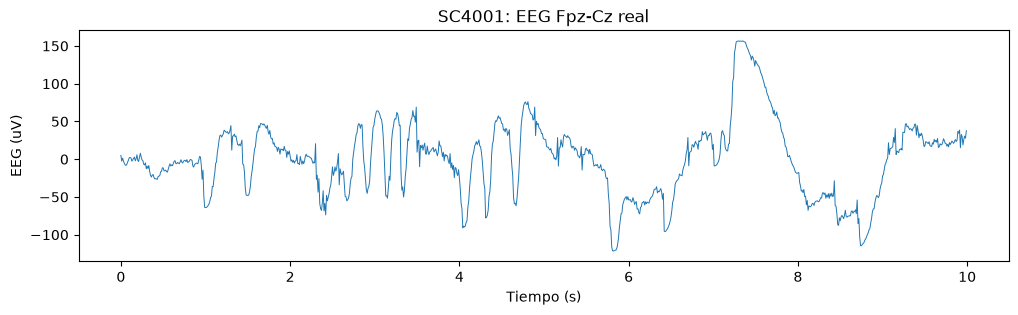

Duración (h): 22.083333333333332
EMG nativo: 1.0 Hz; emg_envelope


In [4]:
from sleep_staging.data.edf import read_recording
record = records.iloc[0]
signals, hypnogram, duration = read_recording(root / record.psg_file, root / record.hyp_file)
signal = signals["eeg_fpz_cz"]
n_samples = int(10 * signal.sfreq)
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(np.arange(n_samples) / signal.sfreq, signal.values[:n_samples], lw=0.7)
ax.set(xlabel="Tiempo (s)", ylabel="EEG (uV)", title=f"{record.recording_id}: EEG Fpz-Cz real")
plt.show()
print("Duración (h):", duration / 3600)
print("EMG nativo:", signals["emg"].sfreq, "Hz;", signals["emg"].kind)
del signals
